In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/axial_t1wce_2_class.yaml
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_101.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_109.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_111.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_117.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_121.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_126.jpg
/kaggle/input/datasets/davidbroberts/brain-tumor-object-detection-datasets/axial_t1wce_2_class/images/test/00018_134.jpg
/kaggle/input/datasets/davidbrobe

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weight & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO('yolo11n.pt')

## 训练轴向 T1 加权成像检测模型

In [5]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/data.yaml \
    epochs = 100 \
    imgsz = 512 \
    batch = 32 \
    device = 0,1

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

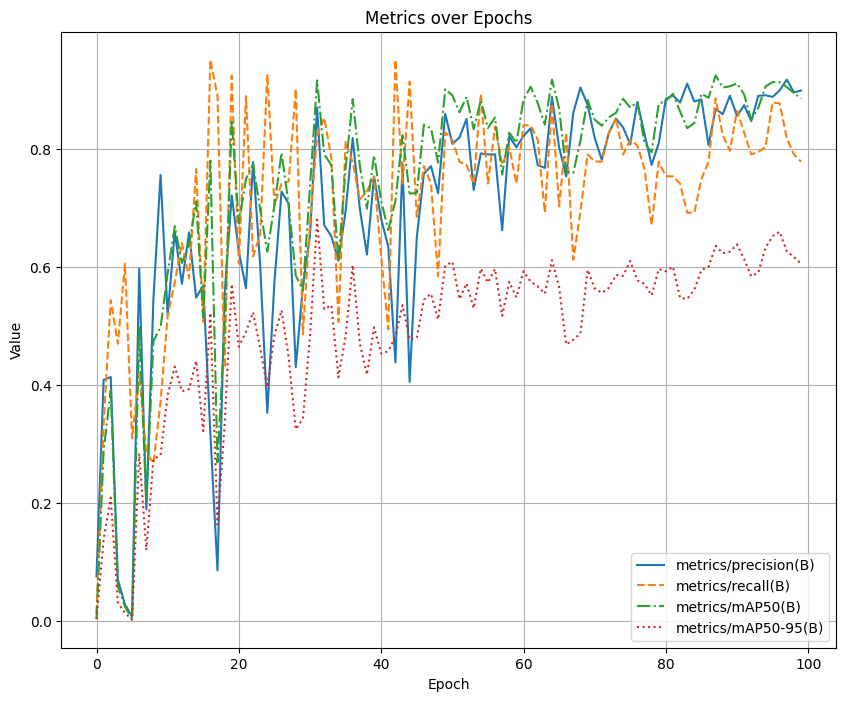

In [6]:
# 从指定路径读取训练结果的 csv 文件到 DataFrame
df = pd.read_csv('/kaggle/working/runs/detect/train/results.csv')

# 定义需要绘制的评估指标列表
metrics_to_plot = [
    'metrics/precision(B)',
    'metrics/recall(B)',
    'metrics/mAP50(B)',
    'metrics/mAP50-95(B)'
]
# 定义不同的线性列表
line_styles = ['-', '--', '-.', ':']
# 检查 DataFrame 中是否包含所有需要绘制的指标
if all(col in df.columns for col in metrics_to_plot):
    # 创建一个新的图形，设置图形大小
    plt.figure(figsize = (10, 8))
    # 遍历每个指标，绘制指标值随迭代次数变化的曲线
    for i, metric in enumerate(metrics_to_plot):
        plt.plot(df.index, df[metric], label = metric, linestyle = line_styles[i % len(line_styles)])
    # 设置 x 轴标签为 'Epoch'
    plt.xlabel('Epoch')
    # 设置 y 轴标签为 'Value'
    plt.ylabel('Value')
    # 设置图形标题
    plt.title('Metrics over Epochs')
    # 添加图例以区分不同的指标曲线
    plt.legend()
    # 启用网络以便更好地观察曲线变化
    plt.grid(True)
    # 显示绘制的图形
    plt.show()
else:
    # 如果 DataFrame 中不包含所有指定的指标，则打印错误信息
    print("Error: Some specified metrics are not present in the DataFrame.")

In [9]:
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')

datasets_path = '/kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class'
train_img_dir = os.path.join(datasets_path, 'train/images')

def pred_images_show(images = train_img_dir, num_sample = 16):
    # 获取图片目录中的所有图片文件名
    image_files = os.listdir(images)
    # 随机选择指定数量的图片文件
    rand_imgs = random.sample(image_files, num_sample)

    # 创建一个 4 * 4 的图布局，用于显示图片
    fig, axes = plt.subplots(4, 4, figsize = (16, 16))
    # 遍历每个样本图片
    for i in range(num_sample):
        # 获取当前图片文件名
        image = rand_imgs[i]
        # 确定当前图片在图布局中的位置
        ax = axes[i // 4, i % 4]
        # 使用模型对当前图片进行预测
        result_predict = model.predict(source = os.path.join(images, image))
        # 将预测结果的图片显示在子图中
        ax.imshow(cv2.cvtColor(result_predict[0].plot(), cv2.COLOR_BGR2RGB))
        # 设置子图的标题
        ax.set_title(image)
        # 关闭子图的坐标轴
        ax.axis('off')
    # 调整图布局，使其紧凑
    plt.tight_layout()
    # 显示图片
    plt.show()


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/train/images/00172_102.jpg: 512x384 1 negative, 8.9ms
Speed: 48.7ms preprocess, 8.9ms inference, 24.1ms postprocess per image at shape (1, 3, 512, 384)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/train/images/00097_65.jpg: 512x512 1 negative, 52.4ms
Speed: 2.9ms preprocess, 52.4ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/train/images/00158_114.jpg: 512x384 1 negative, 9.2ms
Speed: 1.5ms preprocess, 9.2ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 384)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/train/images/00099_139.jpg: 512x512 1 negative, 10.7ms
Speed: 2.2ms preprocess, 10.7ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial

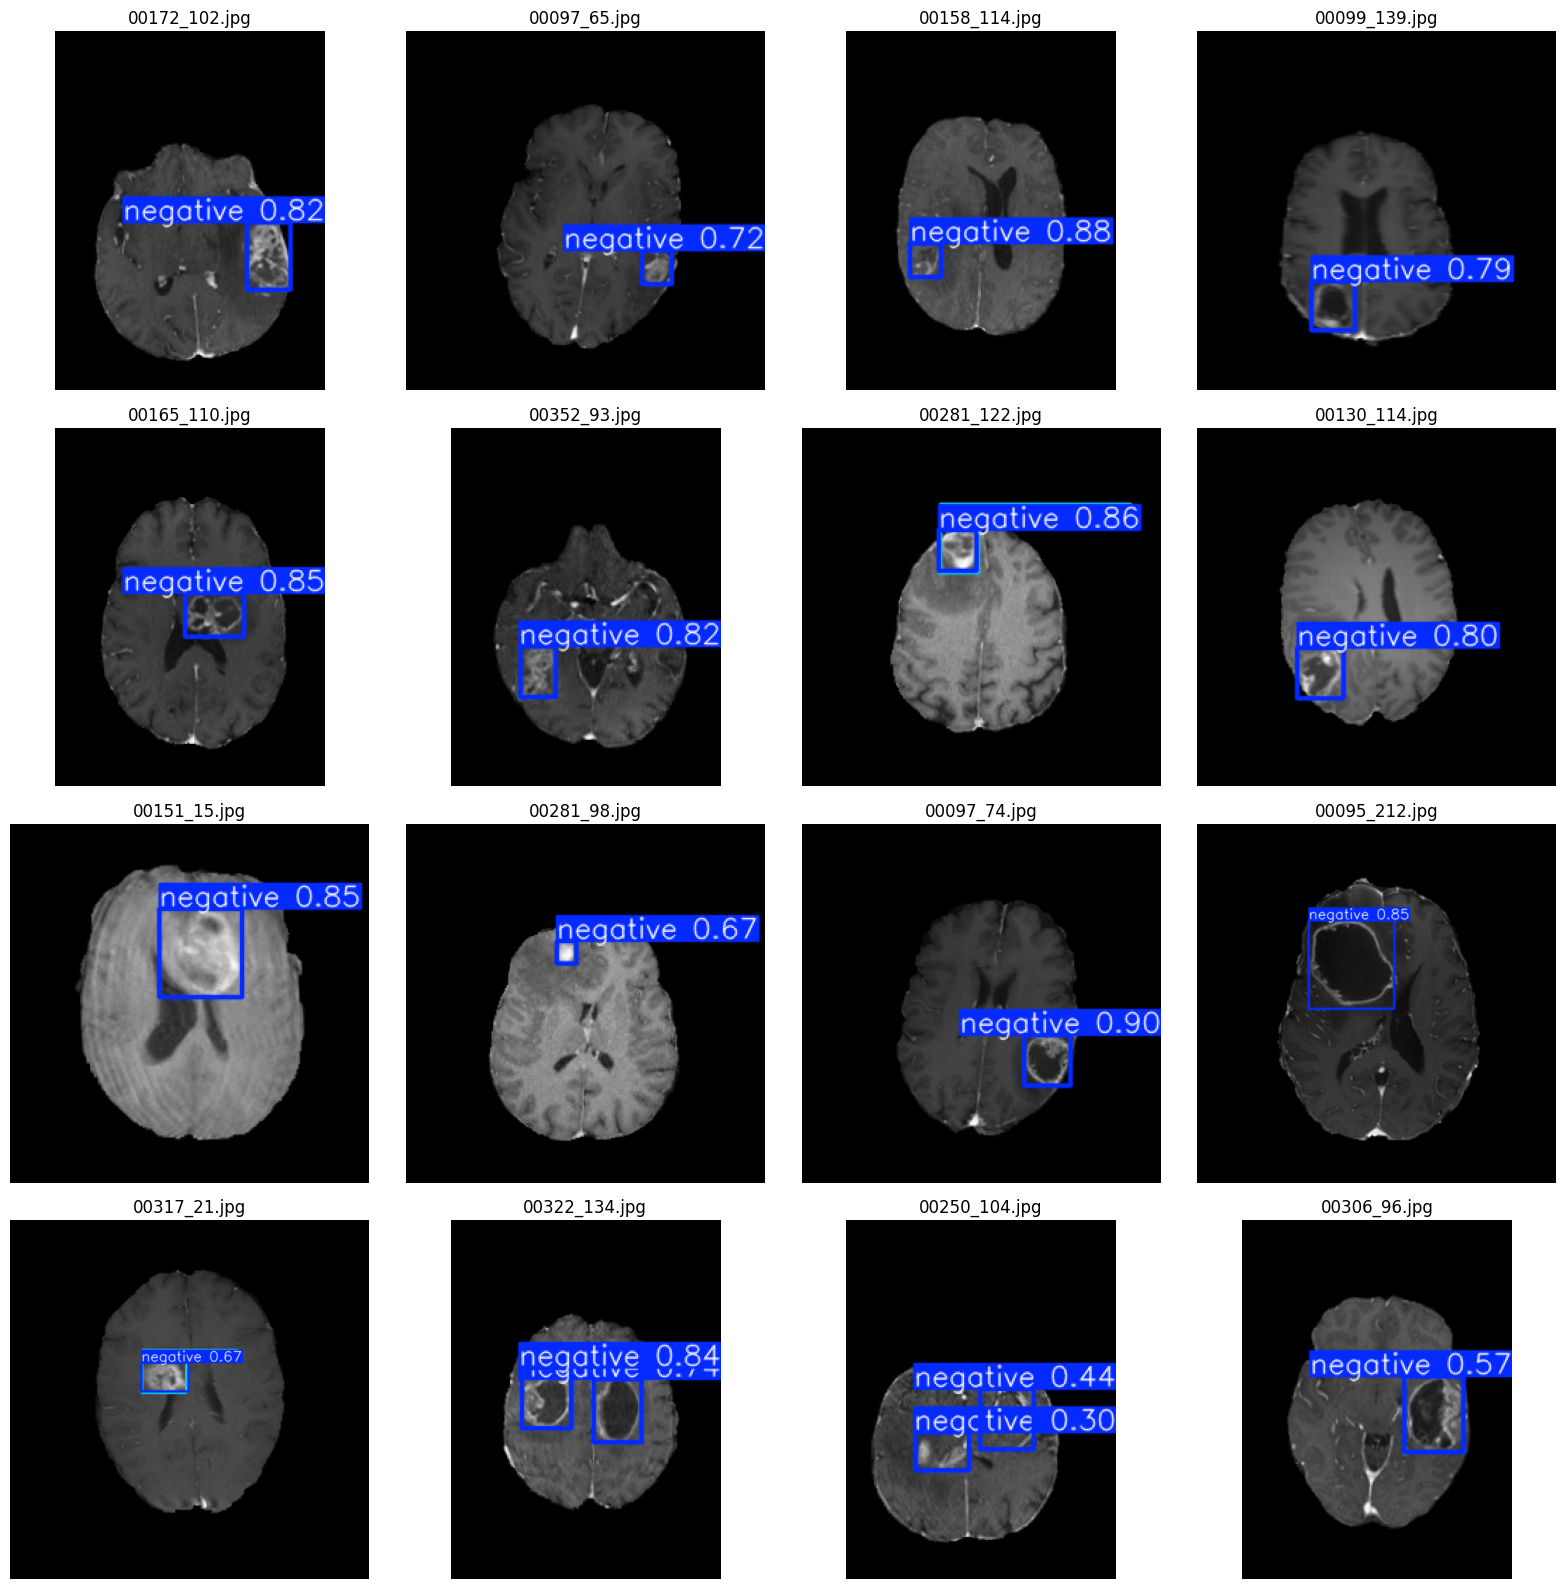

In [10]:
# 调用函数显示预测图片
pred_images_show()


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/val/images/00088_136.jpg: 512x512 1 negative, 11.0ms
Speed: 1.5ms preprocess, 11.0ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/val/images/00061_178.jpg: 512x512 1 negative, 8.7ms
Speed: 0.6ms preprocess, 8.7ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/val/images/00064_220.jpg: 512x512 1 negative, 8.5ms
Speed: 0.6ms preprocess, 8.5ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_class/val/images/00072_81.jpg: 512x512 1 negative, 9.4ms
Speed: 1.1ms preprocess, 9.4ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/axial_t1wce_2_cla

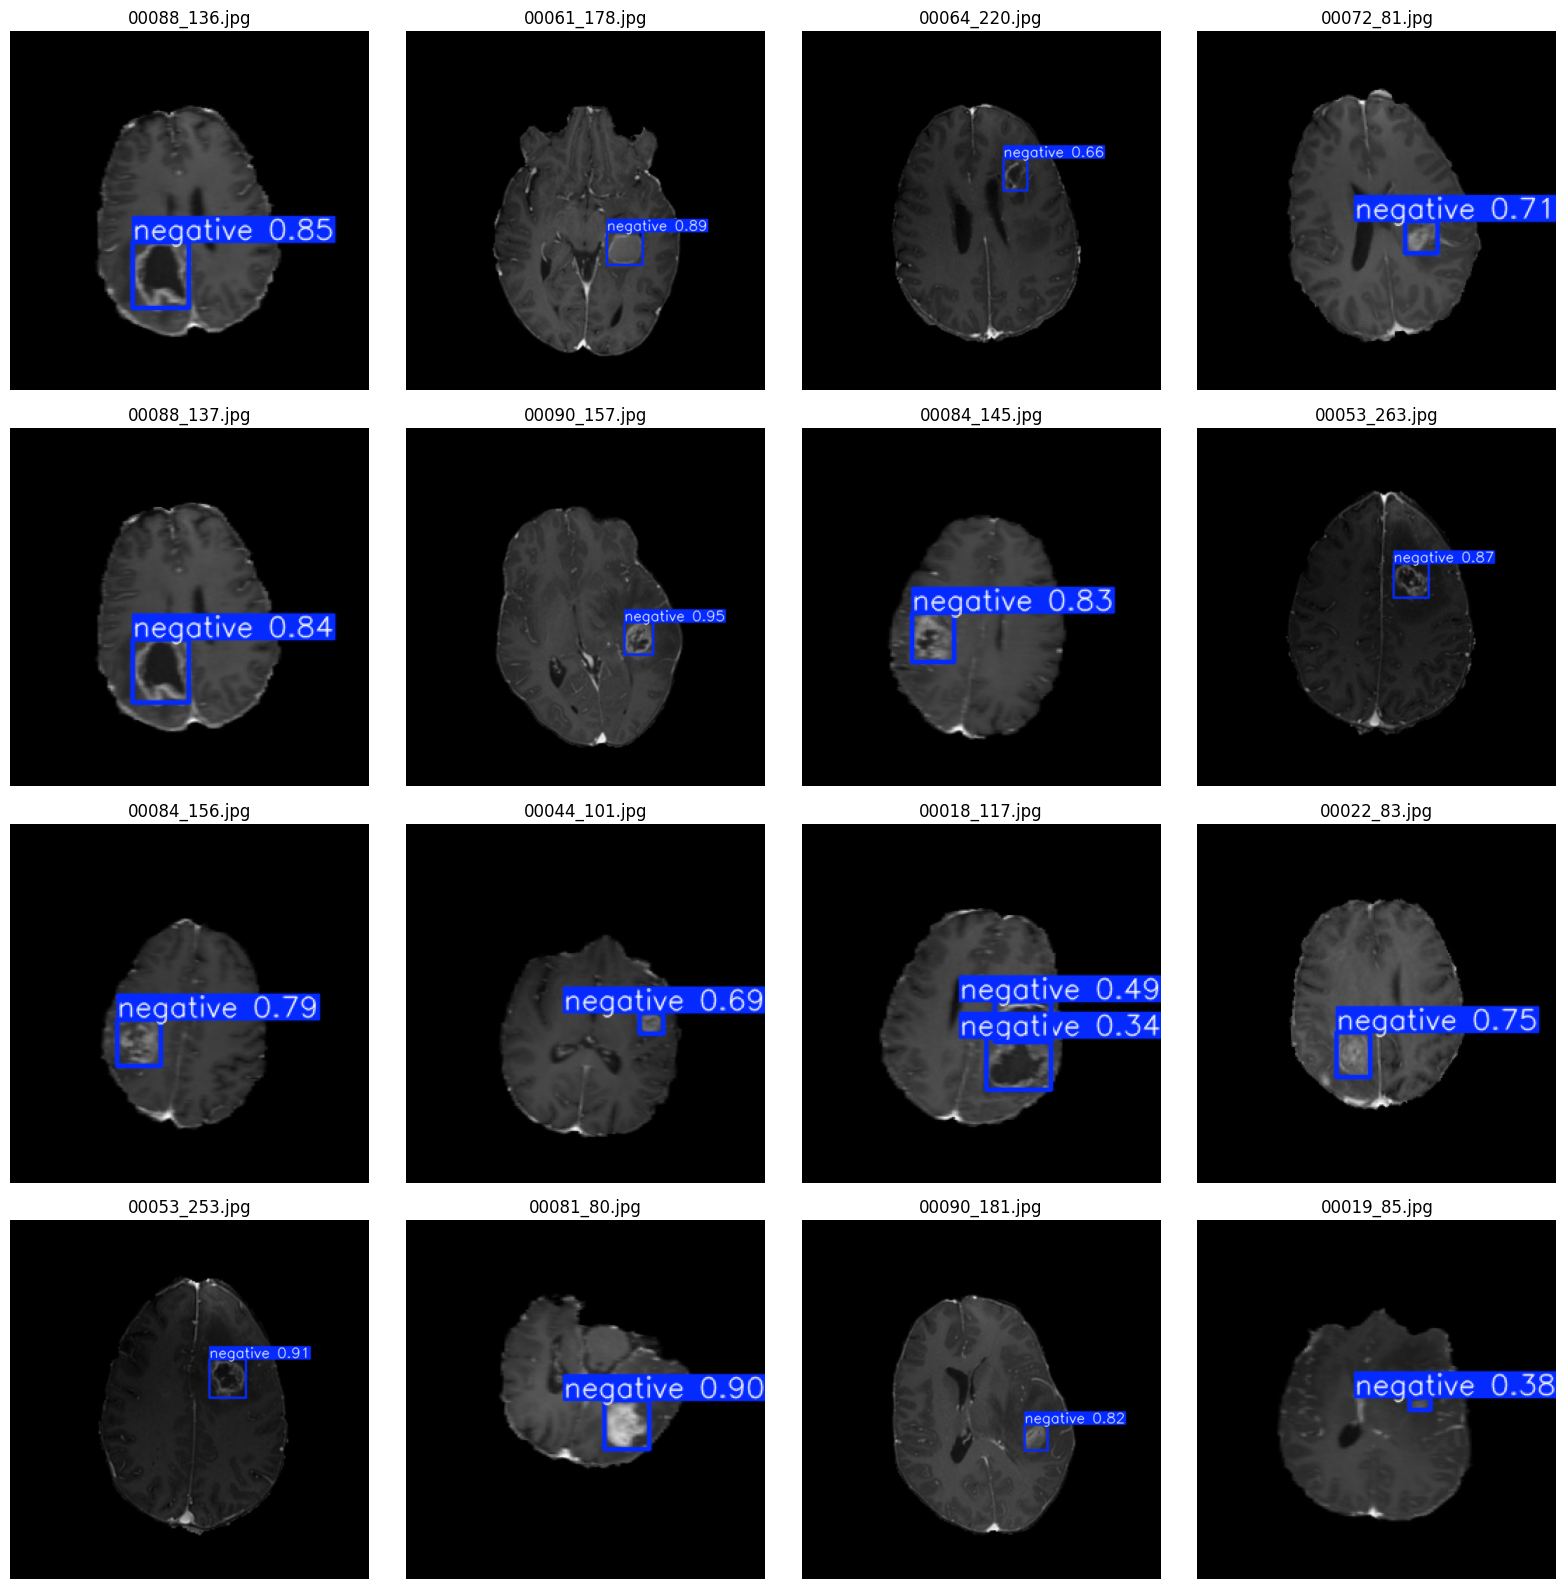

In [11]:
val_img_dir = os.path.join(datasets_path, 'val/images')
# 调用函数显示预测图片
pred_images_show(val_img_dir)

In [12]:
!cp /kaggle/working/runs/detect/train/weights/best.pt axial_t1wce_best.pt

## 训练冠状 T1 加权成像检测模型

In [13]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/data.yaml \
    epochs = 100 \
    imgsz = 512 \
    batch = 32 \
    device = 0,1

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

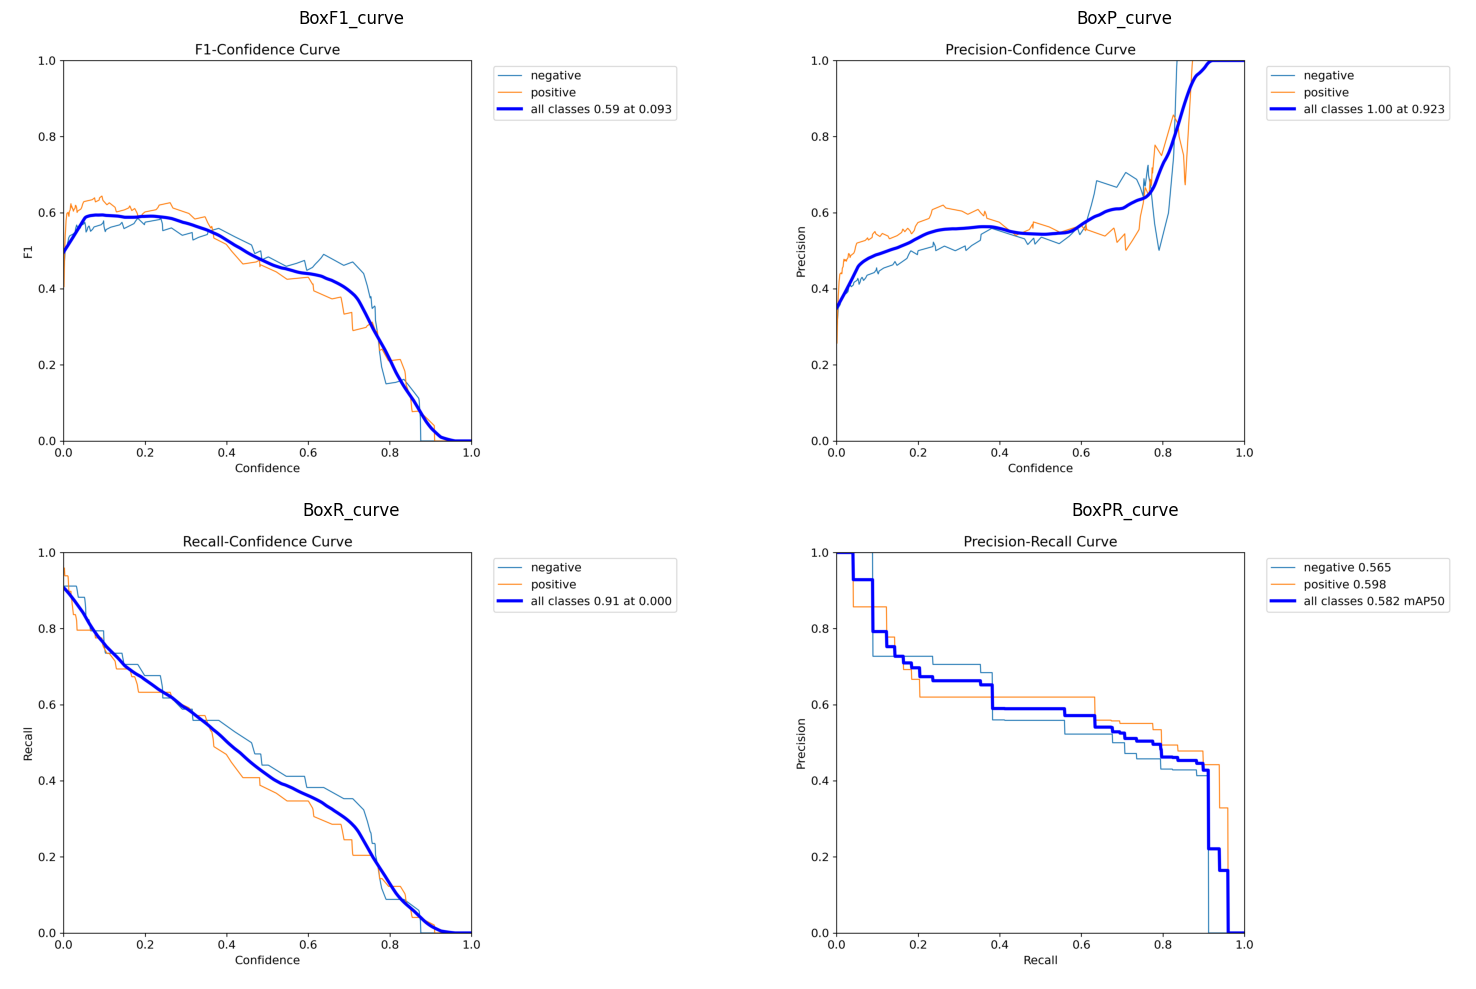

In [15]:
# 指定性能评估曲线的图片所在目录
directory = '/kaggle/working/runs/detect/train-2'

# 定义要展示的图片文件
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 创建一个包含 4 个子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0]) # 设置子图标题为图片文件名（去掉扩展名）
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')
# 调整子图间距
plt.tight_layout()
plt.show()


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/train/images/138.jpg: 512x512 1 negative, 8.6ms
Speed: 1.4ms preprocess, 8.6ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/train/images/61 (6).jpg: 512x512 (no detections), 9.9ms
Speed: 0.9ms preprocess, 9.9ms inference, 0.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/train/images/128 (2).jpg: 512x512 2 negatives, 8.9ms
Speed: 1.1ms preprocess, 8.9ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/train/images/76 (2).jpg: 512x512 1 negative, 8.8ms
Speed: 0.6ms preprocess, 8.8ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1

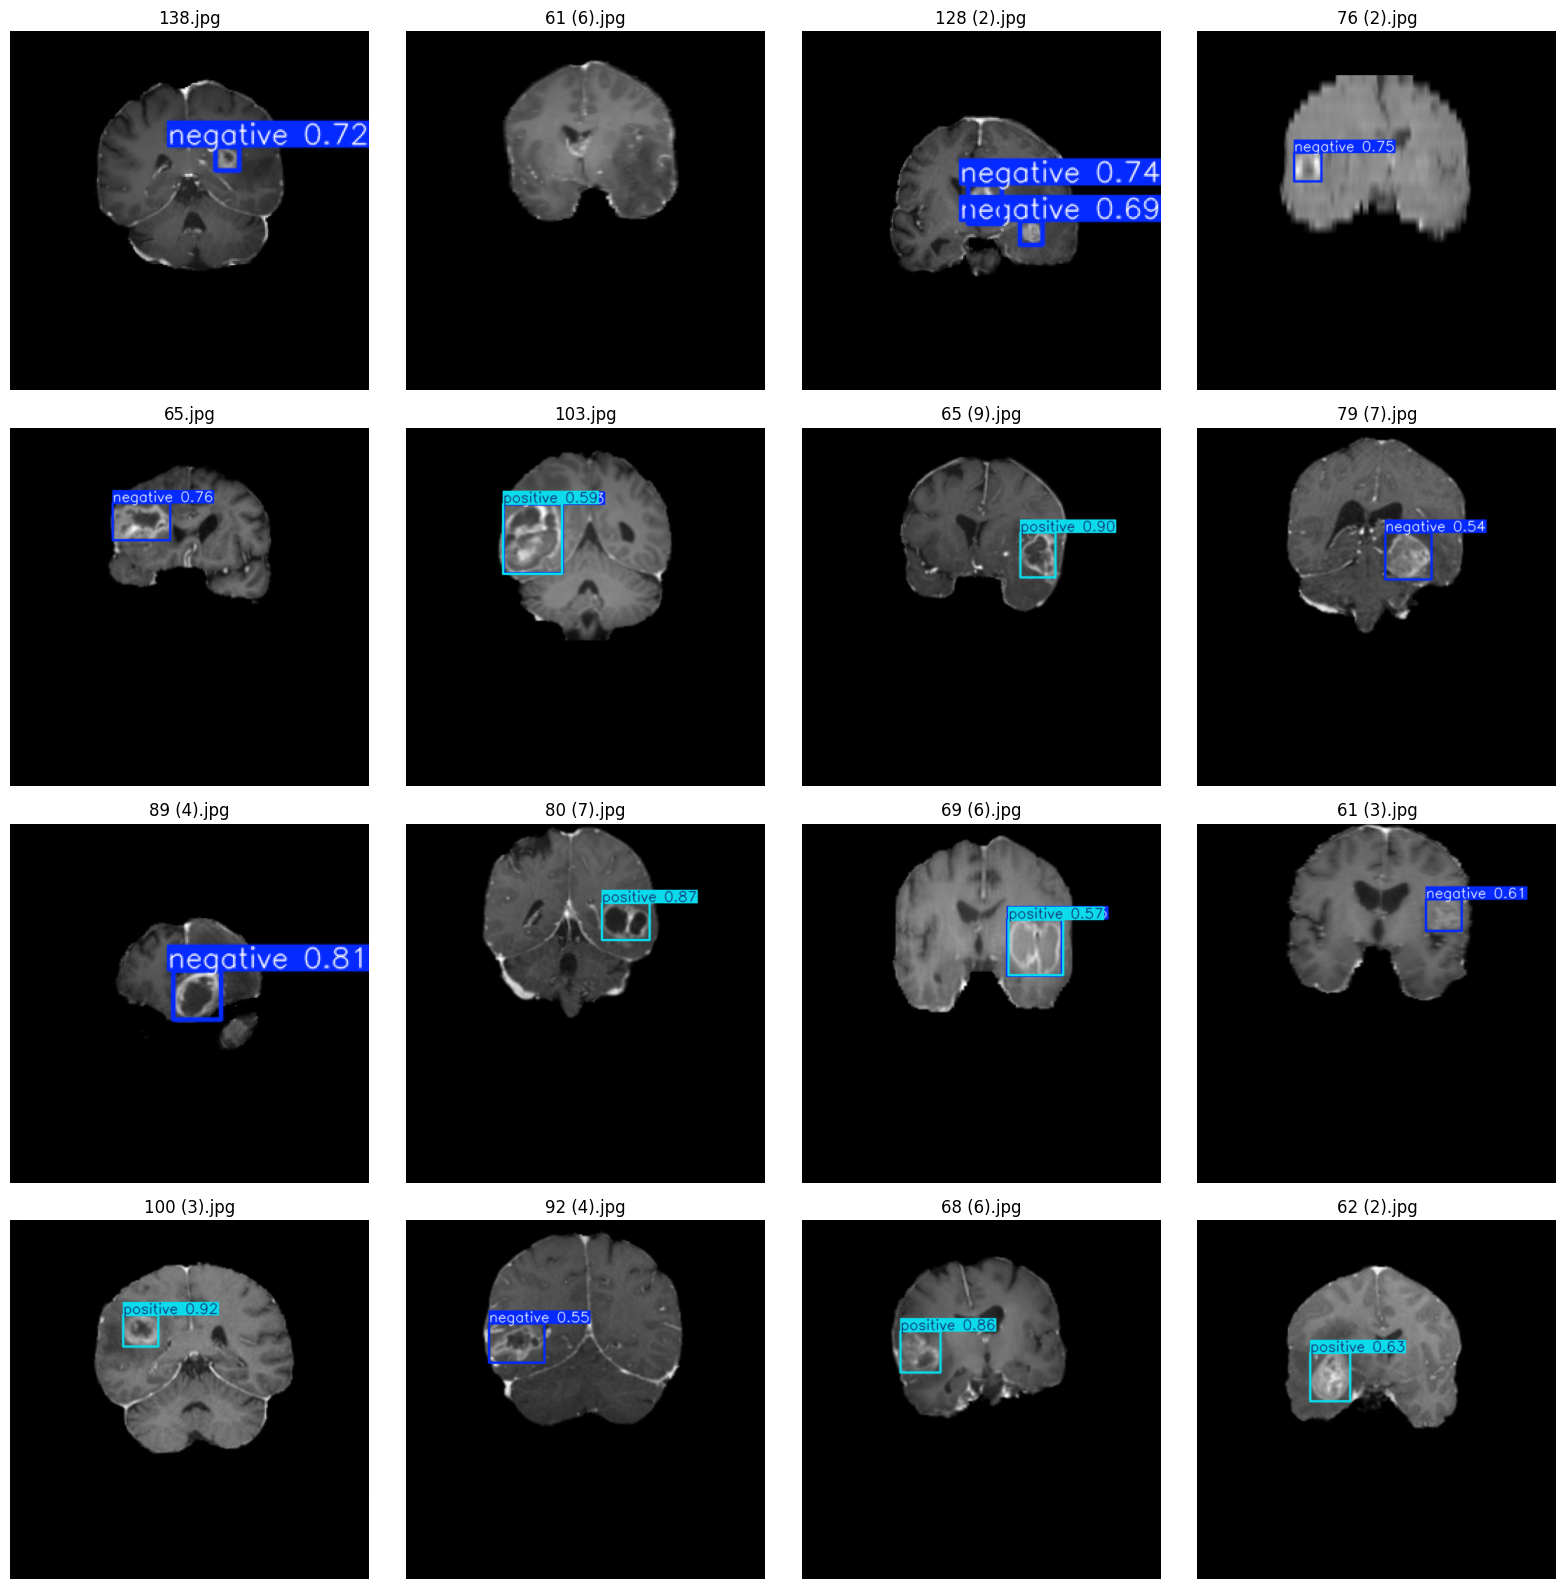

In [16]:
model = YOLO('/kaggle/working/runs/detect/train-2/weights/best.pt')
datasets_path = '/kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class'
train_img_dir = os.path.join(datasets_path, 'train/images')
# 调用函数显示预测图片
pred_images_show(train_img_dir)


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/val/images/51.jpg: 512x512 (no detections), 10.2ms
Speed: 1.3ms preprocess, 10.2ms inference, 0.8ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/val/images/46 (3).jpg: 512x512 1 positive, 10.5ms
Speed: 0.9ms preprocess, 10.5ms inference, 1.9ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/val/images/58 (2).jpg: 512x512 1 negative, 13.0ms
Speed: 0.8ms preprocess, 13.0ms inference, 1.6ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class/val/images/53 (3).jpg: 512x512 1 negative, 9.0ms
Speed: 0.7ms preprocess, 9.0ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2

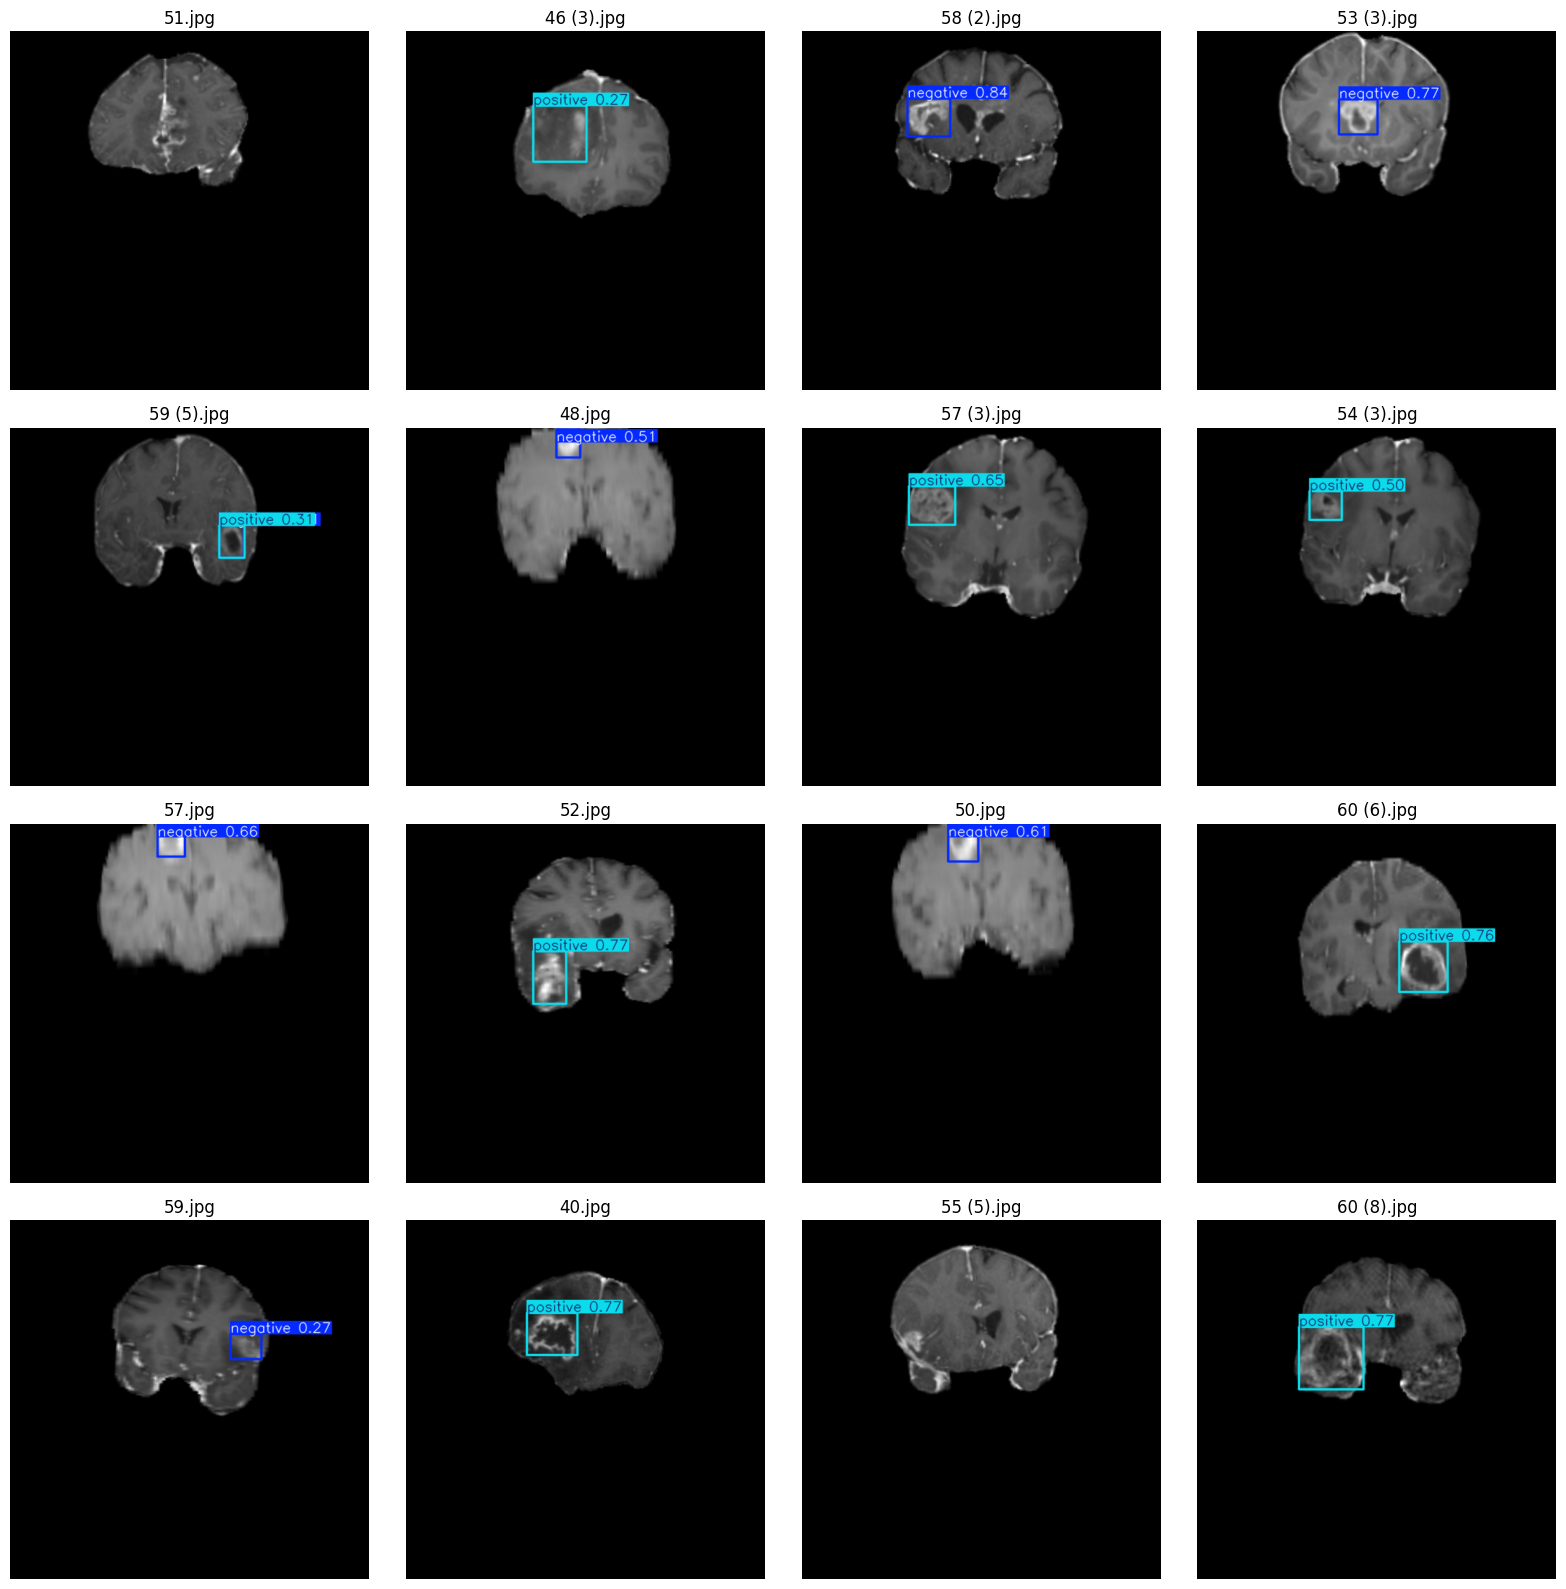

In [17]:
datasets_path = '/kaggle/input/datasets/justinwshj/dataset/datasets/coronal_t1wce_2_class'
val_img_dir = os.path.join(datasets_path, 'val/images')
# 调用函数显示预测图片
pred_images_show(val_img_dir)

In [18]:
!cp /kaggle/working/runs/detect/train-2/weights/best.pt coronal_t1wce_best.pt

## 训练失状位 T1 加权成像检测模型 

In [19]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/data.yaml \
    epochs = 100 \
    imgsz = 512 \
    batch = 32 \
    device = 0,1

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

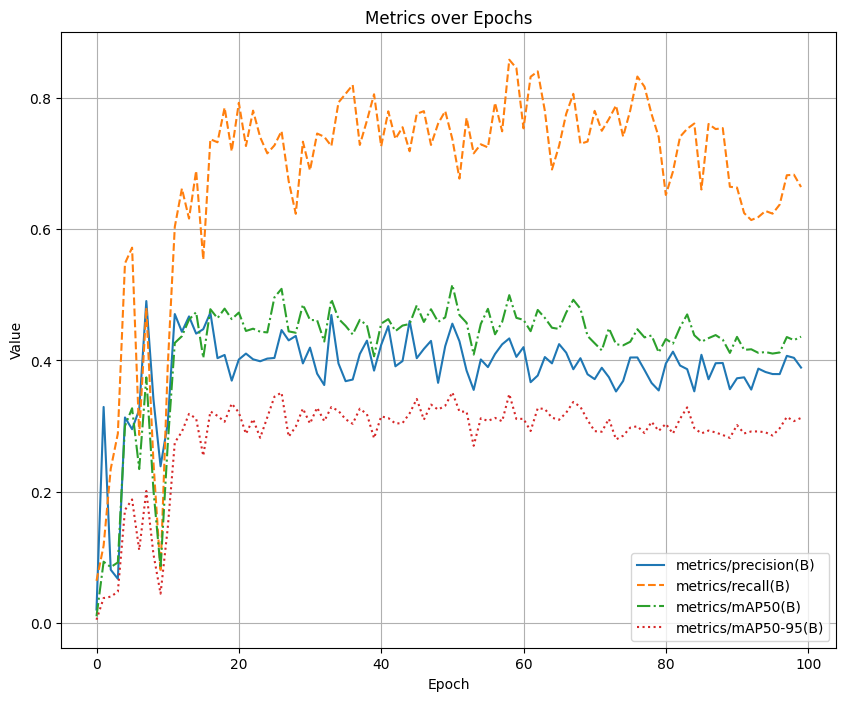

In [20]:
# 从指定路径读取训练结果的 csv 文件到 DataFrame
df = pd.read_csv('/kaggle/working/runs/detect/train-3/results.csv')

# 定义需要绘制的评估指标列表
metrics_to_plot = [
    'metrics/precision(B)',
    'metrics/recall(B)',
    'metrics/mAP50(B)',
    'metrics/mAP50-95(B)'
]
# 定义不同的线性列表
line_styles = ['-', '--', '-.', ':']
# 检查 DataFrame 中是否包含所有需要绘制的指标
if all(col in df.columns for col in metrics_to_plot):
    # 创建一个新的图形，设置图形大小
    plt.figure(figsize = (10, 8))
    # 遍历每个指标，绘制指标值随迭代次数变化的曲线
    for i, metric in enumerate(metrics_to_plot):
        plt.plot(df.index, df[metric], label = metric, linestyle = line_styles[i % len(line_styles)])
    # 设置 x 轴标签为 'Epoch'
    plt.xlabel('Epoch')
    # 设置 y 轴标签为 'Value'
    plt.ylabel('Value')
    # 设置图形标题
    plt.title('Metrics over Epochs')
    # 添加图例以区分不同的指标曲线
    plt.legend()
    # 启用网络以便更好地观察曲线变化
    plt.grid(True)
    # 显示绘制的图形
    plt.show()
else:
    # 如果 DataFrame 中不包含所有指定的指标，则打印错误信息
    print("Error: Some specified metrics are not present in the DataFrame.")


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/train/images/00138_271.jpg: 512x512 1 positive, 9.1ms
Speed: 1.1ms preprocess, 9.1ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/train/images/00054_164.jpg: 512x512 1 negative, 1 positive, 9.3ms
Speed: 0.6ms preprocess, 9.3ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/train/images/00109_85.jpg: 512x512 1 negative, 1 positive, 8.5ms
Speed: 0.6ms preprocess, 8.5ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/train/images/00097_162.jpg: 512x512 1 negative, 10.0ms
Speed: 0.9ms preprocess, 10.0ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/j

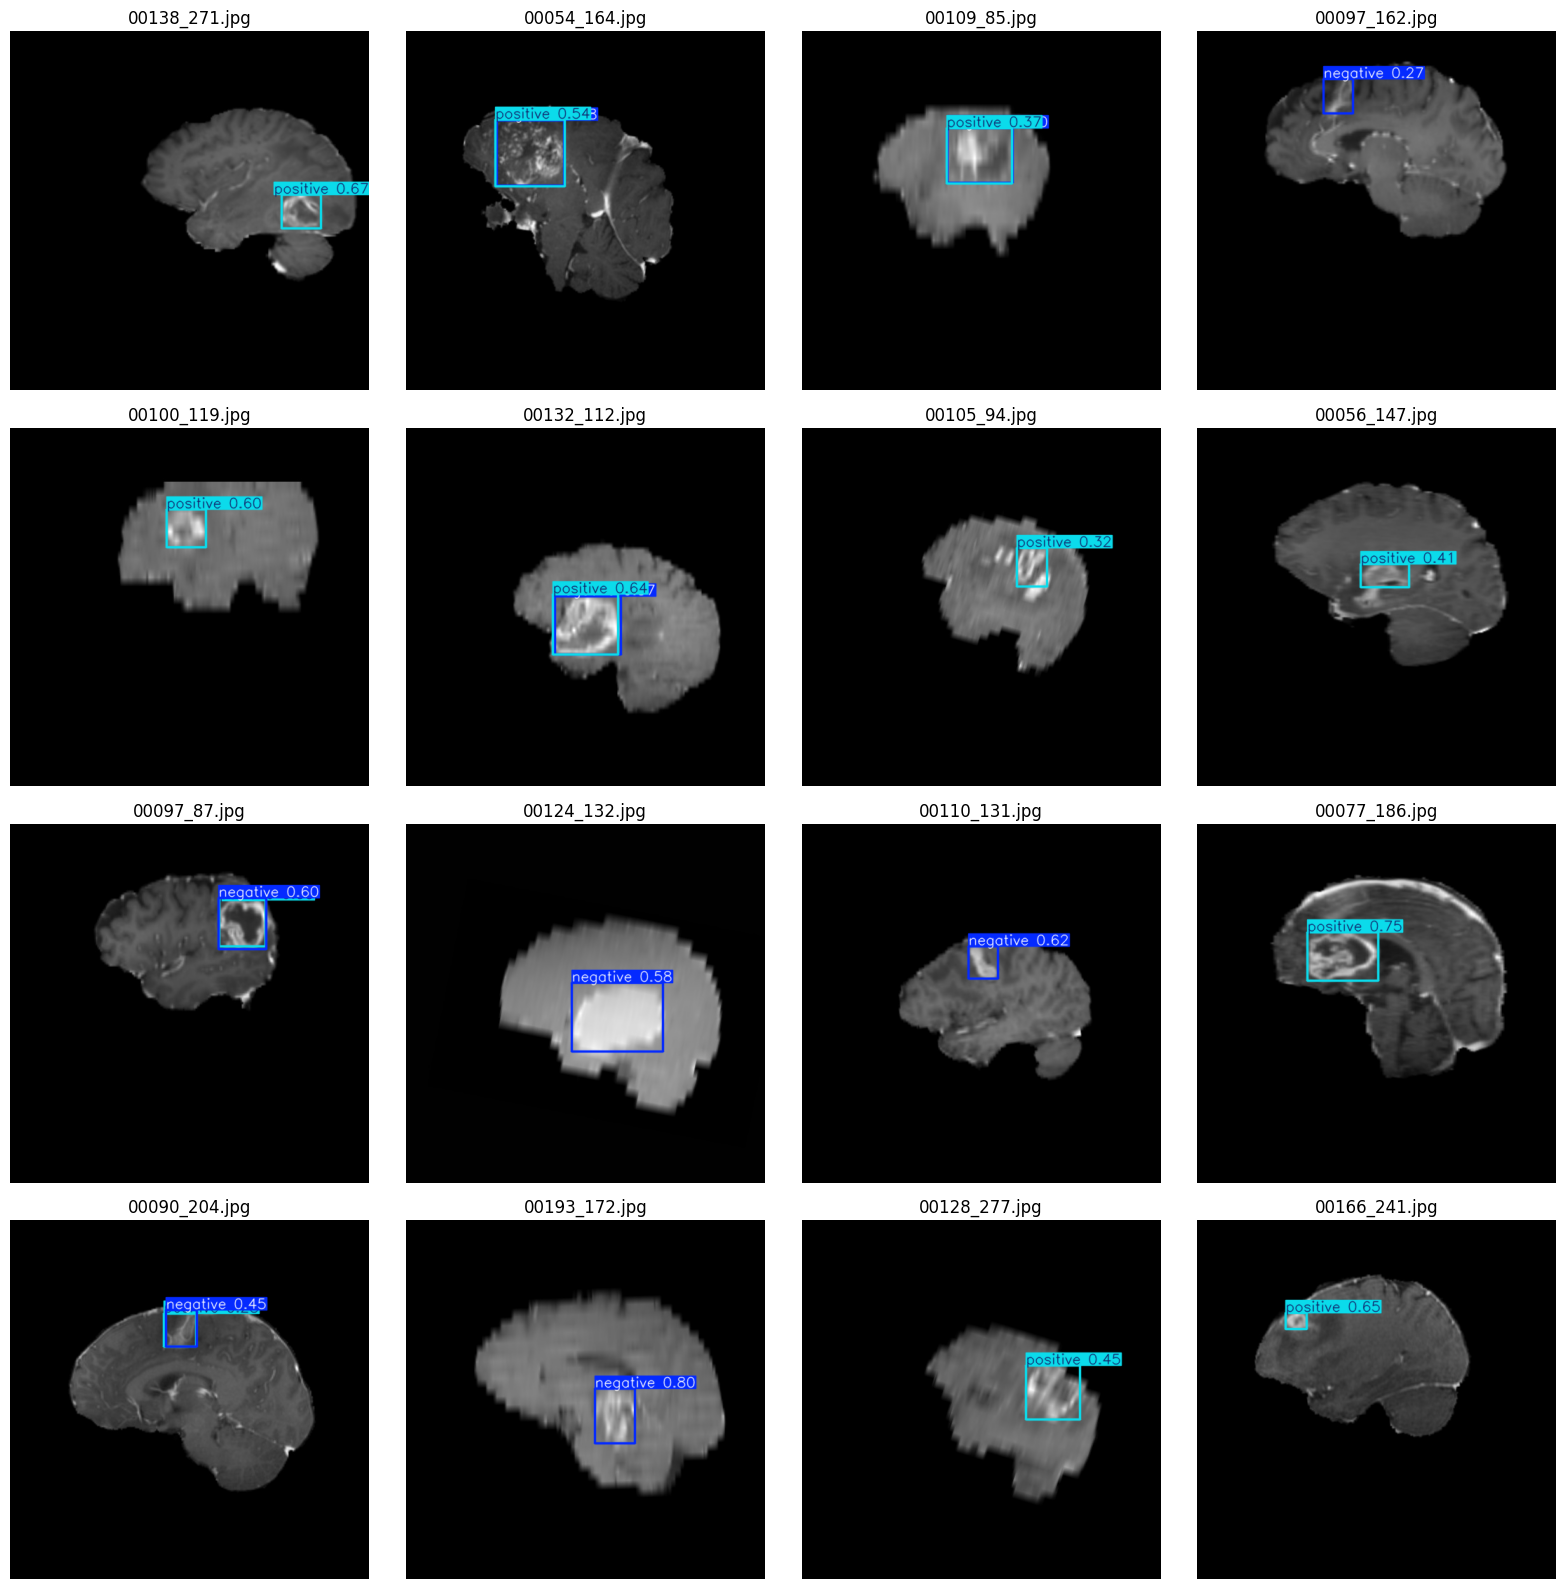

In [21]:
model = YOLO('/kaggle/working/runs/detect/train-3/weights/best.pt')
datasets_path = '/kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class'
train_img_dir = os.path.join(datasets_path, 'train/images')
# 调用函数显示预测图片
pred_images_show(train_img_dir)


image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/val/images/00002_166.jpg: 512x512 1 positive, 12.9ms
Speed: 0.9ms preprocess, 12.9ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/val/images/00035_111.jpg: 512x512 1 negative, 9.6ms
Speed: 0.7ms preprocess, 9.6ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/val/images/00030_257.jpg: 512x512 1 positive, 8.5ms
Speed: 0.5ms preprocess, 8.5ms inference, 1.4ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class/val/images/00030_236.jpg: 512x512 1 positive, 8.5ms
Speed: 0.6ms preprocess, 8.5ms inference, 1.1ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/input/datasets/justinwshj/dataset/datasets/sagi

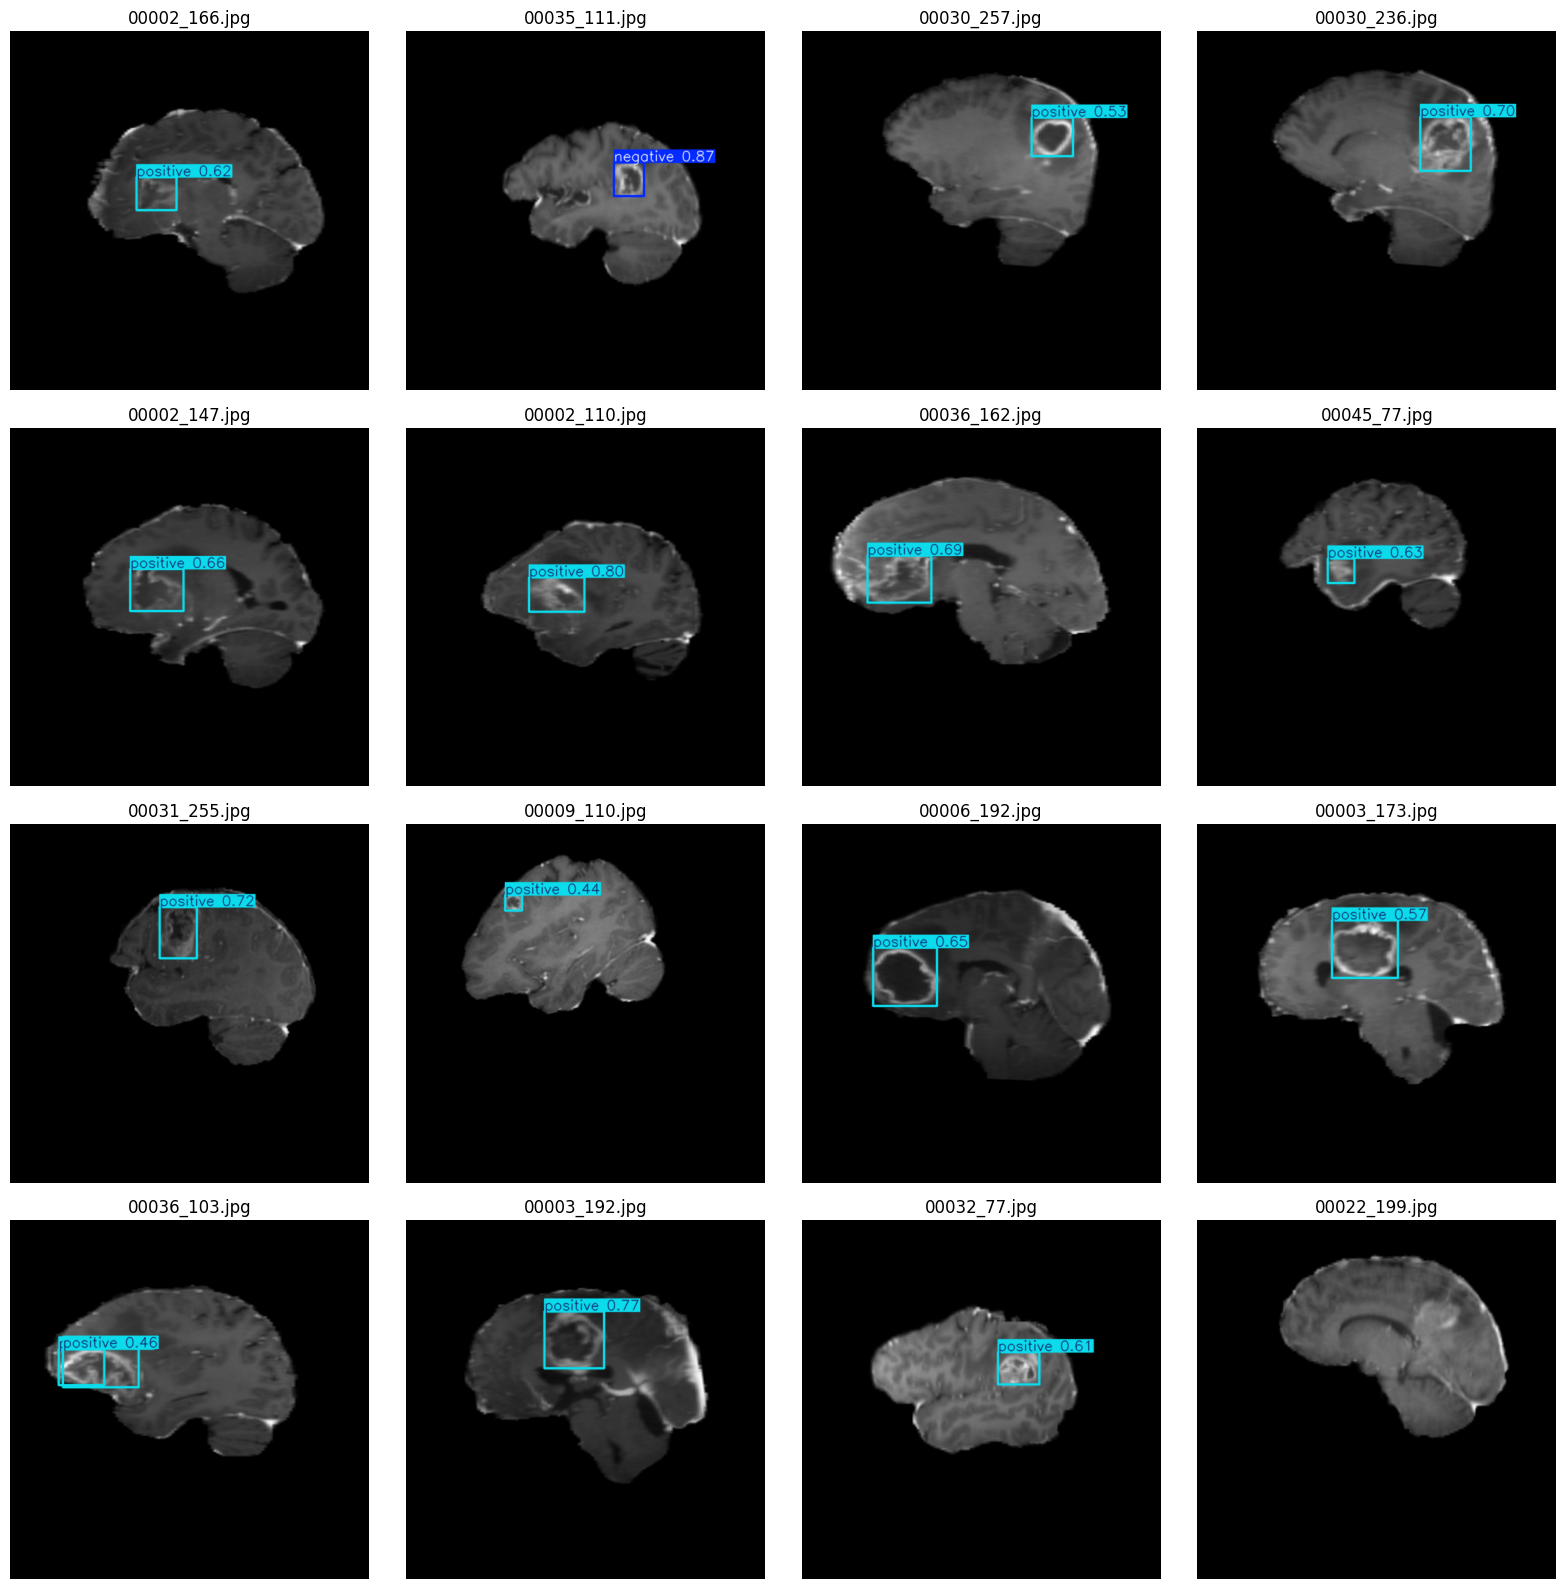

In [22]:
datasets_path = '/kaggle/input/datasets/justinwshj/dataset/datasets/sagittal_t1wce_2_class'
val_img_dir = os.path.join(datasets_path, 'val/images')
# 调用函数显示预测图片
pred_images_show(val_img_dir)

In [23]:
!cp /kaggle/working/runs/detect/train-3/weights/best.pt sagittal_t1wce_best.pt

In [24]:
!zip -q -r results.zip /kaggle/working/*